# Caderno de análise — PQC no ATmega4809 (CMP223)

Caderno de programação literal: cada etapa, do dado bruto à conclusão, fica
registrada aqui e pode ser re-executada (`jupyter nbconvert --execute`).

**Fonte dos dados:** somente observações de **bancada** (`data_source = bench`),
identificadas por `src/analysis/catalog.py` a partir da presença de
`raw/telemetry_*.json` (arquivo gravado apenas pelo `trigger.py` com a placa
conectada). Pastas simuladas, vazias ou legadas são **excluídas**.

**Limitações conhecidas (antes de olhar os números):**
1. *Latência* = tempo medido no host do envio do comando até o 1º byte de
   resposta (`t_exec_ms`). Inclui overhead fixo de USB/UART; o analisador lógico
   (largura do pulso GPIO) refinará isso.
2. *Energia* = **não medida** (shunt e bateria ainda não instalados). Nenhum
   valor de energia é reportado neste caderno.
3. *Clock*: apenas 20 MHz foi coletado na bancada até agora.

In [1]:
import glob, json, os, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy import stats

# Raiz do repositório (o caderno roda a partir de src/analysis/).
ROOT = Path.cwd()
while not (ROOT / ".git").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
EXP = ROOT / "data" / "experiments"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "artigo" / "figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

import subprocess
from matplotlib import font_manager

# Figuras no padrão do artigo (acmsmall): largura de texto = 395,8 pt = 5,5 in,
# fonte Libertinus Serif (sucessora da Linux Libertine do corpo; o OTF da
# Libertine tem métricas verticais quebradas no matplotlib), 8 pt. A fonte é localizada pela
# distribuição TeX (kpsewhich); sem ela, cai para serif genérica.
TEXTW = 395.8225 / 72.27
for f in ("LibertinusSerif-Regular.otf", "LibertinusSerif-Bold.otf", "LibertinusSerif-Italic.otf"):
    try:
        path = subprocess.run(["kpsewhich", f], capture_output=True, text=True).stdout.strip()
        if path:
            font_manager.fontManager.addfont(path)
    except FileNotFoundError:
        pass
sns.set_theme(style="ticks", context="paper")
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Libertinus Serif", "DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.linewidth": 0.6,
    "grid.linewidth": 0.4, "lines.linewidth": 1.0, "axes.grid": True, "grid.alpha": 0.4,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.02, "figure.dpi": 150,
    "axes.formatter.use_locale": False,
})
LABEL = {"kyber512": "Kyber-512", "ctru-light": "CTRU-Light", "ecdh": "ECDH"}
def br(x, nd=1):
    """Número com vírgula decimal (padrão do texto em português)."""
    return f"{x:,.{nd}f}".replace(",", "X").replace(".", ",").replace("X", ".")
PAL = {"kyber512": "#0072B2", "ctru-light": "#D55E00", "ecdh": "#009E73"}  # Okabe-Ito
OPS = {"K": "keygen", "E": "encaps", "D": "decaps", "M": "msgcrypt"}
pd.set_option("display.width", 160)

## 1. Proveniência: quais experimentos entram na análise

In [2]:
cat = pd.read_csv(EXP / "catalog.csv")
display(cat.groupby("source").agg(experimentos=("experiment", "count"),
                                   observacoes=("n_observations", "sum")))
bench_exps = cat.loc[cat.source == "bench", "experiment"].tolist()
bench_exps

,experimentos,observacoes
source,,
bench,8,2000
bench_legacy,4,60
empty,8,0
sim,8,3056


['exp_20261104_224548_exp0_full_raw_2241',
 'exp_20261104_233711_exp0_full_raw_3170',
 'exp_20261104_234001_exp0_full_raw_1522',
 'exp_20261104_234322_kyber512_3110',
 'exp_20261104_234555_kyber512_8736',
 'exp_20261104_235614_all_4877',
 'exp_20261105_001049_complete_simulation_matrix_7223',
 'exp_20261105_072304_full_pqc_campaign_7266']

Apenas `bench` entra. `bench_legacy` foi descartado porque nessas pastas só
sobrou o `runs.csv`, sem a telemetria bruta; o `runs.csv` delas também traz uma
coluna de energia calculada com corrente constante, que **não** é medição.

## 2. Carga da telemetria bruta em formato *tidy*

In [3]:
# telemetry_<alg>_<variant>[_<opt>_<clk>MHz].json ; arquivos antigos sem opt/clk
# foram coletados com -O3 @ 20 MHz (confirmado no schedule.json de cada pasta).
PAT = re.compile(r"telemetry_(?P<alg>kyber512|ctru-light|ecdh)_(?P<variant>asm|ref)"
                 r"(?:_(?P<opt>O3|Os)_(?P<clk>[\d.]+)MHz)?\.json")
rows = []
for e in bench_exps:
    for f in sorted(glob.glob(str(EXP / e / "raw" / "telemetry_*.json"))):
        m = PAT.match(os.path.basename(f)).groupdict()
        for i, r in enumerate(json.load(open(f))):
            rows.append({**r, "experiment": e, "seq": i,
                         "algorithm": m["alg"], "variant": m["variant"],
                         "optimization": "-" + (m["opt"] or "O3"),
                         "clock_mhz": float(m["clk"] or 20)})
df = pd.DataFrame(rows)
df["operation"] = df.cmd.map(OPS)
df["timestamp"] = pd.to_datetime(df.timestamp)
df = df[["experiment", "seq", "timestamp", "algorithm", "variant", "optimization",
         "clock_mhz", "operation", "t_exec_ms", "t_total_ms", "stack_peak",
         "sram_total", "payload_bytes", "kem_validated", "msg_validated", "status"]]
df.to_csv(OUT / "bench_tidy.csv", index=False)
print(len(df), "observações ->", OUT / "bench_tidy.csv")
df.head()

2000 observações -> C:\github\project-csap-cmp223\data\processed\bench_tidy.csv


,experiment,seq,timestamp,algorithm,variant,optimization,clock_mhz,operation,t_exec_ms,t_total_ms,stack_peak,sram_total,payload_bytes,kem_validated,msg_validated,status
0,exp_20261104_224548_exp0_full_raw_2241,0,2026-11-04 22:46:13.906792,kyber512,asm,-O3,20.0,keygen,261.203,331.226,935,6144,800,None,None,OK
1,exp_20261104_224548_exp0_full_raw_2241,1,2026-11-04 22:46:14.377721,kyber512,asm,-O3,20.0,encaps,343.230,413.192,1008,6144,800,None,None,OK
2,exp_20261104_224548_exp0_full_raw_2241,2,2026-11-04 22:46:14.747926,kyber512,asm,-O3,20.0,decaps,316.649,319.974,1019,6144,32,True,None,OK
3,exp_20261104_224548_exp0_full_raw_2241,3,2026-11-04 22:46:14.839977,kyber512,asm,-O3,20.0,msgcrypt,38.368,41.244,68,6144,18,None,True,OK
4,exp_20261104_224548_exp0_full_raw_2241,4,2026-11-04 22:46:15.228782,kyber512,asm,-O3,20.0,keygen,261.436,331.200,935,6144,800,None,None,OK


## 3. Sanidade dos dados (controle experimental)

**Ordem de execução.** O `schedule.json` de cada pasta traz uma ordem
aleatória, mas o modo bench do `run_experiment.py` não a aplica: cada
configuração roda em bloco, com o ciclo fixo K→E→D→M. Por isso o gráfico de
deriva abaixo é a principal evidência de que não há efeito temporal.

In [4]:
print("status:", df.status.value_counts().to_dict())
print("kem_validated (decaps):", df.loc[df.operation == "decaps", "kem_validated"].value_counts(dropna=False).to_dict())
print("msg_validated (msgcrypt):", df.loc[df.operation == "msgcrypt", "msg_validated"].value_counts(dropna=False).to_dict())
# O pico de pilha é determinístico por configuração? (esperado: sim)
sp = df.groupby(["algorithm", "variant", "optimization", "operation"]).stack_peak.nunique()
print("configurações com stack_peak variável:", int((sp > 1).sum()))
df.groupby(["algorithm", "variant", "optimization"]).size().rename("n").to_frame()

status: {'OK': 2000}
kem_validated (decaps): {True: 490, None: 10}
msg_validated (msgcrypt): {True: 500}
configurações com stack_peak variável: 4


n
algorithm  variant optimization     
ctru-light asm     -O3           160
                   -Os           160
           ref     -O3            40
                   -Os            40
kyber512   asm     -O3           660
                   -Os           160
           ref     -O3           620
                   -Os           160

Todas as observações têm `status = OK`. O pico de pilha é constante dentro de cada
configuração, como esperado para código sem alocação dinâmica: a variabilidade
está só na latência. As configurações são **desbalanceadas** (CTRU-Light `ref` tem
menos repetições); por isso usamos ANOVA tipo II e ICs por célula.

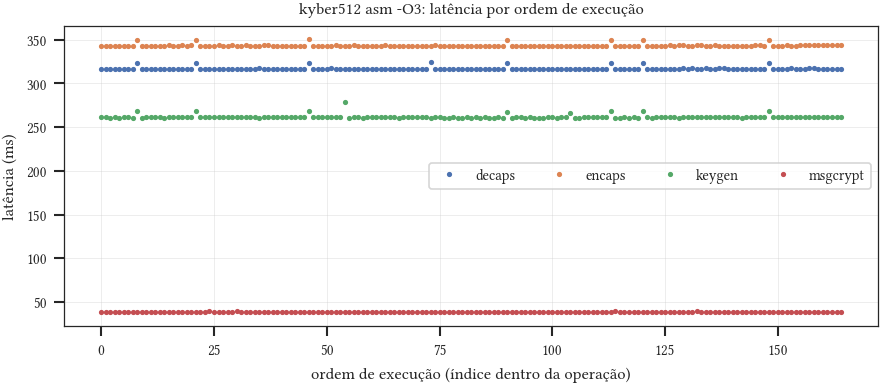

In [5]:
# Deriva temporal ao longo da ordem de execução (Jain cap. 11): sem tendência
# esperada. Um gráfico por configuração para kyber512 asm -O3 (maior N).
fig, ax = plt.subplots(figsize=(7, 2.6))
sub = df[(df.algorithm == "kyber512") & (df.variant == "asm") & (df.optimization == "-O3")]
for op, g in sub.groupby("operation"):
    ax.plot(range(len(g)), g.t_exec_ms.values, ".", ms=3, label=op)
ax.set_xlabel("ordem de execução (índice dentro da operação)"); ax.set_ylabel("latência (ms)")
ax.set_title("kyber512 asm -O3: latência por ordem de execução"); ax.legend(ncol=4, fontsize=7)
fig.savefig(FIG / "drift_kyber_asm.pdf"); fig.savefig(FIG / "drift_kyber_asm.png", dpi=200)

## 4. Sumário estatístico (média, IC 95% t-Student, mediana, IQR)

In [6]:
def summarise(x):
    n = len(x); m = x.mean(); s = x.std(ddof=1)
    h = stats.t.ppf(0.975, n - 1) * s / np.sqrt(n) if n > 1 else np.nan
    q1, q3 = x.quantile([.25, .75])
    return pd.Series({"n": n, "mean_ms": m, "sd_ms": s, "ci95_ms": h,
                      "median_ms": x.median(), "iqr_ms": q3 - q1, "cv_pct": 100 * s / m})

KEYS = ["algorithm", "variant", "optimization", "operation"]
summ = df.groupby(KEYS).t_exec_ms.apply(summarise).unstack()
summ["stack_peak_b"] = df.groupby(KEYS).stack_peak.first()
summ["sram_free_pct"] = 100 * (6144 - summ.stack_peak_b) / 6144
summ["energy_uj"] = np.nan  # NA: shunt ainda não instalado
summ = summ.reset_index()
summ.to_csv(OUT / "summary_bench.csv", index=False)
summ.round(2)

,algorithm,variant,optimization,operation,n,mean_ms,sd_ms,ci95_ms,median_ms,iqr_ms,cv_pct,stack_peak_b,sram_free_pct,energy_uj
0,ctru-light,asm,-O3,decaps,40.0,151.12,0.24,0.08,151.05,0.27,0.16,3177,48.29,NaN
1,ctru-light,asm,-O3,encaps,40.0,91.36,4.28,1.37,89.11,0.61,4.68,2496,59.38,NaN
2,ctru-light,asm,-O3,keygen,40.0,90.98,5.12,1.64,95.32,10.12,5.63,2464,59.90,NaN
3,ctru-light,asm,-O3,msgcrypt,40.0,39.23,0.25,0.08,39.17,0.28,0.65,68,98.89,NaN
4,ctru-light,asm,-Os,decaps,40.0,156.49,1.13,0.36,156.26,0.32,0.72,3137,48.94,NaN
5,ctru-light,asm,-Os,encaps,40.0,93.87,4.69,1.50,91.40,0.57,5.00,2460,59.96,NaN
6,ctru-light,asm,-Os,keygen,40.0,93.42,5.46,1.75,98.03,10.62,5.84,2432,60.42,NaN
7,ctru-light,asm,-Os,msgcrypt,40.0,41.70,0.23,0.07,41.64,0.30,0.56,36,99.41,NaN
8,ctru-light,ref,-O3,decaps,10.0,272.79,0.23,0.17,272.73,0.17,0.08,3049,50.37,NaN
9,ctru-light,ref,-O3,encaps,10.0,139.95,4.29,3.07,137.95,0.17,3.06,2376,61.33,NaN


## 5. Flash ocupada (artefato de compilação, independente da bancada)

In [7]:
def hex_bytes(path):
    # Soma dos bytes dos registros de dados (tipo 00) do Intel HEX = .text + .data.
    n = 0
    for line in open(path):
        if line.startswith(":") and line[7:9] == "00":
            n += int(line[1:3], 16)
    return n

HP = re.compile(r"firmware-(?P<alg>kyber512|ctru-light|ecdh)-(?P<variant>asm|ref)-[\d.]+MHz-(?P<opt>O3|Os)\.hex")
hx = []
for f in sorted(glob.glob(str(EXP / "exp_*" / "bin" / "*.hex"))):  # ordem cronológica
    m = HP.match(os.path.basename(f))
    if m:
        hx.append({**m.groupdict(), "flash_b": hex_bytes(f), "src": Path(f).parts[-3]})
flash = (pd.DataFrame(hx).groupby(["alg", "variant", "opt"]).last().reset_index()
         .rename(columns={"alg": "algorithm", "opt": "optimization"}))
flash["optimization"] = "-" + flash.optimization
flash["flash_free_pct"] = 100 * (49152 - flash.flash_b) / 49152
flash.to_csv(OUT / "flash_sizes.csv", index=False)
flash

,algorithm,variant,optimization,flash_b,src,flash_free_pct
0,ctru-light,asm,-O3,28794,exp_20261105_072304_full_pqc_campaign_7266,41.418457
1,ctru-light,asm,-Os,23116,exp_20261105_072304_full_pqc_campaign_7266,52.970378
2,ctru-light,ref,-O3,47140,exp_20261105_072304_full_pqc_campaign_7266,4.093424
3,ctru-light,ref,-Os,40938,exp_20261105_072304_full_pqc_campaign_7266,16.711426
4,ecdh,asm,-O3,14806,exp_20261105_072304_full_pqc_campaign_7266,69.877116
5,ecdh,asm,-Os,9622,exp_20261105_000725_complete_simulation_matrix...,80.423991
6,ecdh,ref,-O3,38752,exp_20261105_000725_complete_simulation_matrix...,21.158854
7,ecdh,ref,-Os,10792,exp_20261105_000725_complete_simulation_matrix...,78.043620
8,kyber512,asm,-O3,26256,exp_20261105_072304_full_pqc_campaign_7266,46.582031
9,kyber512,asm,-Os,15414,exp_20261105_072304_full_pqc_campaign_7266,68.640137


O ECDH aparece aqui porque o firmware **compila** (o `.hex` é gerado mesmo nas
execuções simuladas), mas não há telemetria de bancada dele: as campanhas que
o incluíam terminaram sem gerar `telemetry_ecdh_*.json` (causa ainda não
investigada). Ele entra só na comparação de
Flash. Usamos o `.hex` mais recente de cada configuração; não verificamos se todos
vieram do mesmo commit do firmware.

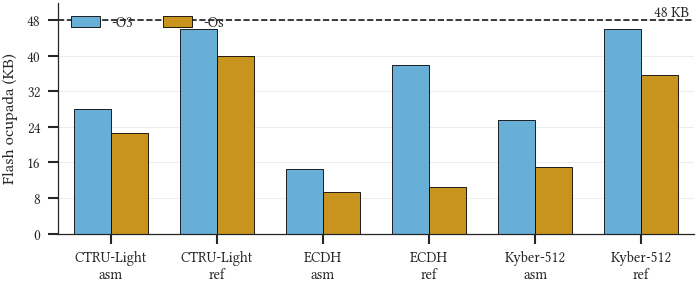

In [8]:
fl = flash.assign(cfg=flash.algorithm.map(LABEL) + "\n" + flash.variant)
fig, ax = plt.subplots(figsize=(TEXTW, 2.0))
sns.barplot(data=fl, x="cfg", y="flash_b", hue="optimization", ax=ax,
            palette=["#56B4E9", "#E69F00"], width=0.7, edgecolor="black", linewidth=0.4)
ax.axhline(49152, color="k", ls="--", lw=0.8)
ax.text(5.45, 49152, "48 KB", fontsize=7, va="bottom", ha="right")
ax.set_xlabel(""); ax.set_ylabel("Flash ocupada (KB)")
ax.set_yticks([k * 8192 for k in range(7)])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1024:.0f}"))
ax.set_ylim(0, 53248); ax.legend(title="", frameon=False, ncol=2, loc="upper left")
sns.despine(fig)
fig.savefig(FIG / "flash.pdf"); fig.savefig(FIG / "flash.png", dpi=300)

## 6. Latência por configuração (média ± IC 95%)

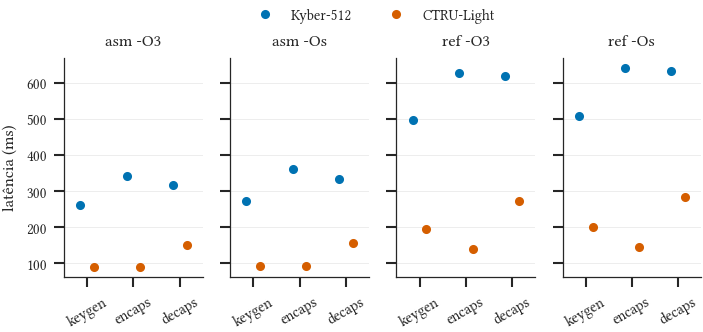

In [9]:
kem = df[df.operation != "msgcrypt"].copy()
kem["cfg"] = kem.variant + " " + kem.optimization
cols = ["asm -O3", "asm -Os", "ref -O3", "ref -Os"]
fig, axs = plt.subplots(1, 4, figsize=(TEXTW, 1.9), sharey=True)
for ax, cfg in zip(axs, cols):
    sub_ = kem[kem.cfg == cfg]
    sns.pointplot(data=sub_, x="operation", y="t_exec_ms", hue="algorithm", ax=ax,
                  order=["keygen", "encaps", "decaps"], hue_order=["kyber512", "ctru-light"],
                  palette=PAL, errorbar=("ci", 95), dodge=0.3, linestyle="none",
                  markersize=3, err_kws={"linewidth": 0.8}, legend=(cfg == cols[0]))
    ax.set_title(cfg); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
axs[0].set_ylabel("latência (ms)")
h, l = axs[0].get_legend_handles_labels(); axs[0].get_legend().remove()
fig.legend(h, [LABEL[x] for x in l], loc="upper center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, 1.10))
sns.despine(fig)
fig.savefig(FIG / "latency.pdf"); fig.savefig(FIG / "latency.png", dpi=300)

## 7. Comparação de alternativas (Welch, razão de médias em escala log)

In [10]:
def compare(a, b):
    # Razão das médias geométricas b/a com IC 95% (Welch sobre log).
    la, lb = np.log(a), np.log(b)
    d = lb.mean() - la.mean()
    se = np.sqrt(la.var(ddof=1) / len(la) + lb.var(ddof=1) / len(lb))
    dof = se**4 / ((la.var(ddof=1) / len(la))**2 / (len(la) - 1) + (lb.var(ddof=1) / len(lb))**2 / (len(lb) - 1))
    h = stats.t.ppf(0.975, dof) * se
    p = stats.ttest_ind(lb, la, equal_var=False).pvalue
    return np.exp(d), np.exp(d - h), np.exp(d + h), p

def table(factor, base, alt, fixed):
    out = []
    for keys, grp in kem.groupby([k for k in KEYS if k != factor]):
        a = grp.loc[grp[factor] == base, "t_exec_ms"]; b = grp.loc[grp[factor] == alt, "t_exec_ms"]
        if len(a) > 1 and len(b) > 1:
            r, lo, hi, p = compare(a, b)
            out.append({**dict(zip([k for k in KEYS if k != factor], keys)),
                        f"razao_{alt}/{base}": r, "ic_lo": lo, "ic_hi": hi, "p_welch": p})
    return pd.DataFrame(out)

ref_vs_asm = table("variant", "asm", "ref", None)
os_vs_o3 = table("optimization", "-O3", "-Os", None)
kyb_vs_ctru = table("algorithm", "ctru-light", "kyber512", None)
for name, t in [("ref/asm", ref_vs_asm), ("-Os/-O3", os_vs_o3), ("kyber/ctru", kyb_vs_ctru)]:
    t.to_csv(OUT / f"cmp_{name.replace('/', '_vs_').replace('-', '')}.csv", index=False)
    print("\n==", name); display(t.round(4))


== ref/asm


,algorithm,optimization,operation,razao_ref/asm,ic_lo,ic_hi,p_welch
0,ctru-light,-O3,decaps,1.8051,1.8038,1.8065,0.0
1,ctru-light,-O3,encaps,1.5328,1.4953,1.5712,0.0
2,ctru-light,-O3,keygen,2.1422,2.0888,2.1969,0.0
3,ctru-light,-Os,decaps,1.8148,1.8106,1.8191,0.0
4,ctru-light,-Os,encaps,1.5490,1.5082,1.5909,0.0
5,ctru-light,-Os,keygen,2.1423,2.0863,2.1998,0.0
6,kyber512,-O3,decaps,1.9591,1.9570,1.9613,0.0
7,kyber512,-O3,encaps,1.8306,1.8289,1.8324,0.0
8,kyber512,-O3,keygen,1.9039,1.9011,1.9067,0.0
9,kyber512,-Os,decaps,1.9006,1.8972,1.9039,0.0



== -Os/-O3


,algorithm,variant,operation,razao_-Os/-O3,ic_lo,ic_hi,p_welch
0,ctru-light,asm,decaps,1.0355,1.0331,1.0379,0.0000
1,ctru-light,asm,encaps,1.0273,1.0060,1.0490,0.0124
2,ctru-light,asm,keygen,1.0266,1.0006,1.0534,0.0454
3,ctru-light,ref,decaps,1.0411,1.0401,1.0420,0.0000
4,ctru-light,ref,encaps,1.0382,1.0081,1.0691,0.0154
5,ctru-light,ref,keygen,1.0267,1.0002,1.0539,0.0485
6,kyber512,asm,decaps,1.0543,1.0528,1.0558,0.0000
7,kyber512,asm,encaps,1.0544,1.0528,1.0561,0.0000
8,kyber512,asm,keygen,1.0472,1.0454,1.0490,0.0000
9,kyber512,ref,decaps,1.0228,1.0212,1.0244,0.0000



== kyber/ctru


,variant,optimization,operation,razao_kyber512/ctru-light,ic_lo,ic_hi,p_welch
0,asm,-O3,decaps,2.0974,2.0956,2.0993,0.0
1,asm,-O3,encaps,3.7647,3.7103,3.8199,0.0
2,asm,-O3,keygen,2.8812,2.8294,2.9340,0.0
3,asm,-Os,decaps,2.1355,2.1301,2.1410,0.0
4,asm,-Os,encaps,3.8642,3.8045,3.9248,0.0
5,asm,-Os,keygen,2.9390,2.8840,2.9949,0.0
6,ref,-O3,decaps,2.2764,2.2741,2.2786,0.0
7,ref,-O3,encaps,4.4963,4.4008,4.5938,0.0
8,ref,-O3,keygen,2.5608,2.5118,2.6108,0.0
9,ref,-Os,decaps,2.2364,2.2332,2.2397,0.0


## 8. Modelo linear (ANOVA fatorial sobre log da latência)

Modelo: $\log(T) = \mu + \text{alg} + \text{variante} + \text{opt} + \text{op} + \text{interações} + \varepsilon$,
somente KEM (keygen/encaps/decaps; `msgcrypt` é um XOR com o segredo, fora do KEM).
O log transforma efeitos multiplicativos (speedup) em aditivos e estabiliza a
variância entre configurações com latências muito diferentes. A fração da
soma de quadrados explicada por cada termo ($\eta^2$) mostra quais fatores
dominam o desempenho.

In [11]:
kem["logT"] = np.log(kem.t_exec_ms)
fit = smf.ols("logT ~ C(algorithm) * C(variant) * C(optimization) * C(operation)", data=kem).fit()
aov = sm.stats.anova_lm(fit, typ=2)
aov["eta2"] = aov.sum_sq / aov.sum_sq.sum()
aov = aov.sort_values("eta2", ascending=False)
aov.to_csv(OUT / "anova_latency.csv")
print(f"R² = {fit.rsquared:.5f}   n = {int(fit.nobs)}")
aov.round(5)

R² = 0.99906   n = 1500


,sum_sq,df,F,PR(>F),eta2
C(algorithm),233.65388,1.0,691404.62132,0.00000,0.57752
C(variant),137.66285,1.0,407357.79744,0.00000,0.34026
C(operation),18.22862,2.0,26970.12970,0.00000,0.04506
C(algorithm):C(operation),13.06317,2.0,19327.60405,0.00000,0.03229
C(algorithm):C(variant):C(operation),0.56042,2.0,829.16266,0.00000,0.00139
C(variant):C(operation),0.50437,2.0,746.24600,0.00000,0.00125
Residual,0.49880,1476.0,NaN,NaN,0.00123
C(optimization),0.31803,1.0,941.07713,0.00000,0.00079
C(algorithm):C(variant),0.03979,1.0,117.75384,0.00000,0.00010
C(variant):C(optimization),0.02998,1.0,88.70756,0.00000,0.00007


In [12]:
# Modelo aditivo (sem interações): coeficientes interpretáveis como fatores multiplicativos.
add = smf.ols("logT ~ C(algorithm) + C(variant) + C(optimization) + C(operation)", data=kem).fit()
coef = pd.DataFrame({"fator_multiplicativo": np.exp(add.params),
                     "ic_lo": np.exp(add.conf_int()[0]), "ic_hi": np.exp(add.conf_int()[1])})
print(f"R² aditivo = {add.rsquared:.4f}")
coef.round(4)

R² aditivo = 0.9708


,fator_multiplicativo,ic_lo,ic_hi
Intercept,119.2715,117.4807,121.0895
C(algorithm)[T.kyber512],2.8764,2.8370,2.9164
C(variant)[T.ref],1.8761,1.8560,1.8963
C(optimization)[T.-Os],1.0352,1.0226,1.0479
C(operation)[T.encaps],0.9323,0.9205,0.9441
C(operation)[T.keygen],0.7704,0.7607,0.7802


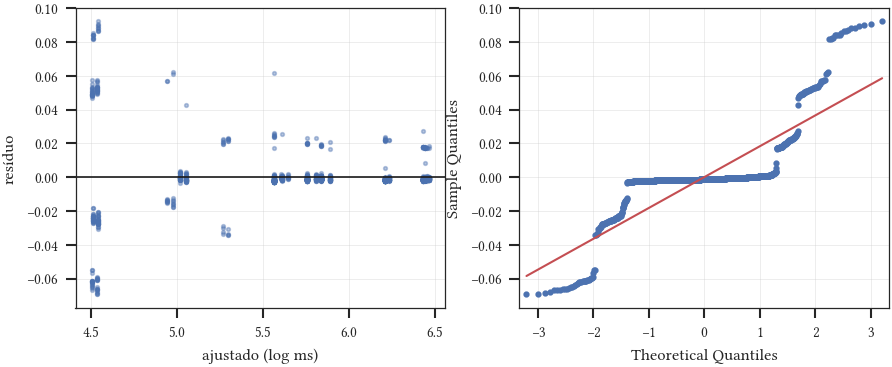

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(7, 2.6))
axs[0].scatter(fit.fittedvalues, fit.resid, s=3, alpha=.4); axs[0].axhline(0, c="k", lw=.8)
axs[0].set_xlabel("ajustado (log ms)"); axs[0].set_ylabel("resíduo")
sm.qqplot(fit.resid, line="s", ax=axs[1], markersize=2); axs[1].set_title("")
fig.savefig(FIG / "residuals.pdf"); fig.savefig(FIG / "residuals.png", dpi=200)

## 9. Trade-off memória × latência

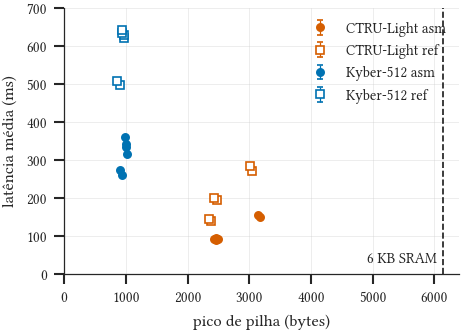

In [14]:
s = summ[summ.operation != "msgcrypt"]
fig, ax = plt.subplots(figsize=(TEXTW * 0.62, 2.3))
for (alg, var), g in s.groupby(["algorithm", "variant"]):
    ax.errorbar(g.stack_peak_b, g.mean_ms, yerr=g.ci95_ms, fmt="o" if var == "asm" else "s",
                color=PAL[alg], mfc=PAL[alg] if var == "asm" else "white", ms=3.5, mew=0.8,
                capsize=1.5, elinewidth=0.6, linestyle="none", label=f"{LABEL[alg]} {var}")
ax.axvline(6144, color="k", ls="--", lw=0.8)
ax.text(6050, 20, "6 KB SRAM", ha="right", va="bottom", fontsize=7)
ax.set_xlabel("pico de pilha (bytes)"); ax.set_ylabel("latência média (ms)")
ax.set_xlim(0, 6400); ax.set_ylim(0, 700); ax.legend(frameon=False, loc="upper right")
sns.despine(fig)
fig.savefig(FIG / "tradeoff.pdf"); fig.savefig(FIG / "tradeoff.png", dpi=300)

## 9b. Tabelas exportadas para o artigo (`artigo/tables/`)

In [15]:
TAB = ROOT / "artigo" / "tables"; TAB.mkdir(parents=True, exist_ok=True)
t = summ[summ.operation != "msgcrypt"].set_index(["algorithm", "variant", "optimization", "operation"])
fl = flash.set_index(["algorithm", "variant", "optimization"]).flash_b
lines = [r"\begin{tabular}{@{}lllrrrrrr@{}}", r"\toprule",
         r" & & & \multicolumn{3}{c}{Latência (ms), média $\pm$ IC 95\%} & & & \\",
         r"\cmidrule(lr){4-6}",
         r"Algoritmo & Var. & Otim. & KeyGen & Encaps & Decaps & Pilha (B) & Flash (KB) & $N$ \\",
         r"\midrule"]
for k, alg in enumerate(["kyber512", "ctru-light"]):
    if k: lines.append(r"\addlinespace")
    first = True
    for var in ["asm", "ref"]:
        for opt in ["-O3", "-Os"]:
            r = t.loc[(alg, var, opt)]
            cells = [f"{br(r.loc[o, 'mean_ms'])} $\\pm$ {br(r.loc[o, 'ci95_ms'])}" for o in ["keygen", "encaps", "decaps"]]
            lines.append(" & ".join([LABEL[alg] if first else "", var, f"$-${opt[1:]}", *cells,
                                     f"{int(r.stack_peak_b.max()):,}".replace(",", "."),
                                     br(fl.loc[(alg, var, opt)] / 1024),
                                     str(int(r.n.min()))]) + r" \\")
            first = False
lines += [r"\bottomrule", r"\end{tabular}"]
(TAB / "results.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

NOME = {"algorithm": "Algoritmo", "variant": "Implementação", "optimization": "Otimização",
        "operation": "Operação"}
def termo(i):
    return r" $\times$ ".join(NOME[f.strip()[2:-1]] for f in i.split(":"))
top = aov.drop(index="Residual").head(6)
lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
         r"Termo & GL & $F$ & $\eta^2$ (\%) \\", r"\midrule"]
for i, r in top.iterrows():
    lines.append(f"{termo(i)} & {int(r.df)} & {br(r.F, 0)} & {br(100 * r.eta2, 2)} \\\\")
r = aov.loc["Residual"]
lines += [r"\midrule", f"Resíduo & {int(r.df)} & -- & {br(100 * r.eta2, 2)} \\\\",
          r"\bottomrule", r"\end{tabular}"]
(TAB / "anova.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
print((TAB / "results.tex").read_text(encoding="utf-8")); print((TAB / "anova.tex").read_text(encoding="utf-8"))

\begin{tabular}{@{}lllrrrrrr@{}}
\toprule
 & & & \multicolumn{3}{c}{Latência (ms), média $\pm$ IC 95\%} & & & \\
\cmidrule(lr){4-6}
Algoritmo & Var. & Otim. & KeyGen & Encaps & Decaps & Pilha (B) & Flash (KB) & $N$ \\
\midrule
Kyber-512 & asm & $-$O3 & 261,7 $\pm$ 0,3 & 343,6 $\pm$ 0,2 & 317,0 $\pm$ 0,2 & 1.019 & 25,6 & 165 \\
 & asm & $-$Os & 274,1 $\pm$ 0,4 & 362,3 $\pm$ 0,5 & 334,2 $\pm$ 0,4 & 997 & 15,1 & 40 \\
 & ref & $-$O3 & 498,3 $\pm$ 0,5 & 629,0 $\pm$ 0,5 & 621,0 $\pm$ 0,5 & 976 & 46,1 & 155 \\
 & ref & $-$Os & 508,9 $\pm$ 0,8 & 642,2 $\pm$ 0,9 & 635,1 $\pm$ 0,8 & 939 & 35,6 & 40 \\
\addlinespace
CTRU-Light & asm & $-$O3 & 91,0 $\pm$ 1,6 & 91,4 $\pm$ 1,4 & 151,1 $\pm$ 0,1 & 3.177 & 28,1 & 40 \\
 & asm & $-$Os & 93,4 $\pm$ 1,7 & 93,9 $\pm$ 1,5 & 156,5 $\pm$ 0,4 & 3.137 & 22,6 & 40 \\
 & ref & $-$O3 & 194,7 $\pm$ 3,7 & 140,0 $\pm$ 3,1 & 272,8 $\pm$ 0,2 & 3.049 & 46,0 & 10 \\
 & ref & $-$Os & 199,9 $\pm$ 4,1 & 145,3 $\pm$ 3,5 & 284,0 $\pm$ 0,2 & 3.009 & 40,0 & 10 \\
\bottomrule


## 10. Interpretação

*Texto escrito sobre os resultados da execução de 2026-11-05 (2000 observações
de bancada, 20 MHz). Se os dados mudarem, revisar os números abaixo.*

**Quais fatores dominam a latência.** Na ANOVA sobre $\log T$, o algoritmo
explica ~58% da variação e a variante (asm × ref) ~34%. A operação e a
interação algoritmo×operação explicam ~8% juntas. A otimização do compilador
(-Os × -O3) explica < 0,1%. O modelo completo tem $R^2 > 0{,}99$: os fatores
controlados explicam quase toda a variação, então o ruído de medição é pequeno
perto dos efeitos estudados.

**Assembly AVR.** A variante `asm` é 1,5×–2,1× mais rápida que `ref` em todas
as células, com ICs estreitos. Ela também reduz muito a Flash: Kyber -O3 cai de
47,2 KB (só 4% livre) para 26,3 KB. Sem `asm`, o Kyber `ref -O3` praticamente
não cabe junto com uma aplicação.

**-Os × -O3.** -Os é só 2–5% mais lento, mas economiza de 6 a 11 KB de Flash.
No ATmega4809, onde a Flash é o recurso escasso, -Os é a escolha dominante.

**Kyber-512 × CTRU-Light.** O CTRU-Light é 2,1×–4,5× mais rápido (o maior
ganho é no encaps), mas usa cerca de 3× mais pilha: ~3,1 KB contra ~1,0 KB,
deixando ~48% da SRAM livre contra ~84%. Isso é um *trade-off* real: o
CTRU-Light troca memória por tempo.

**Variabilidade.** O CV fica abaixo de 1% em quase todas as células. A
exceção é keygen/encaps do CTRU-Light (CV de 3–6%, mediana > média e
IQR ≈ 10 ms), que sugere uma distribuição bimodal, provavelmente por amostragem
com rejeição no algoritmo. Ainda não verificamos no código. O `msgcrypt` (XOR com o
segredo, o mesmo código em todos os firmwares) fica entre 38,4 e 39,2 ms em todas as
configurações -O3 e varia só com a otimização: serve de controle de que a
medição é estável entre campanhas e firmwares.

**Limitações.** (1) A latência inclui o overhead serial do host; as razões
entre configurações são menos afetadas do que os valores absolutos. (2) Só
20 MHz foi coletado: o fator clock não entra no modelo. (3) Energia não medida
(shunt pendente). (4) Sem dados de bancada do ECDH. (5) Células
desbalanceadas (N de 10 a 165). (6) Os resíduos não são normais nas células
bimodais; com N grande e efeitos desta magnitude, as conclusões não dependem
disso.